# Регрессионный анализ в Python

**Дисциплина:** Введение в анализ больших данных

Линейная регрессия:

$$
Y' = b_0 + b_1 x_1 + \ldots + b_k x_k
$$

- $Y'$ — предсказанные значения;
- $b_0, b_1, \ldots$ — коэффициенты (МНК);
- остаток $d = Y - Y'$.

**Проверка модели:** F-тест, t-тесты коэффициентов, анализ остатков (нормальность, автокорреляция, гомоскедастичность, MSE).

Инструмент: **`statsmodels`** (`ols`).

Демо на датасете **penguins** (масса тела ~ длина плавника и клюва).

## 0. Импорт


In [2]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import acorr_breusch_godfrey, het_breuschpagan

plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")


---
## 1. Данные и предварительный анализ

Цель: объяснить `body_mass_g` через `flipper_length_mm` и `bill_length_mm`.


In [7]:
df = pd.read_csv("Turtle.csv", sep=";")
df.head()


,length,width,height,weight
0,98,81,38,155
1,103,84,38,160
2,103,86,42,164
3,105,86,42,165
4,109,88,44,170


In [8]:
print("=== Shapiro–Wilk ===")
for c in df.columns:
    W, p = stats.shapiro(df[c])
    print(f"{c:20s}: W={W:.4f}, p={p:.4g}")

print("\nКорреляции (Spearman):")
print(df.corr(method="spearman").round(3))


=== Shapiro–Wilk ===
length              : W=0.9144, p=0.07736
width               : W=0.9648, p=0.6441
height              : W=0.9682, p=0.7169
weight              : W=0.9528, p=0.4109

Корреляции (Spearman):
        length  width  height  weight
length   1.000  0.933   0.940   0.975
width    0.933  1.000   0.936   0.959
height   0.940  0.936   1.000   0.964
weight   0.975  0.959   0.964   1.000


Из результатов мы видим, что результаты нормальны

`W находится в {0; 1}`, чем ближе к 1, тем больше выборка походит на нормальное распределение, иначе выборка ненормальна

Также видим, что у нас все ситуации, где `p > 0.05`, следовательно H0 не отвергаем, нет варианта `p < 0.05`

H0 - выборка нормальна

Матрица корреляции с сильной связью между весом и остальными признаками (самая сильная связь)


---
## 2. Множественная линейная регрессия

```text
smf.ols("y ~ x1 + x2", data=df).fit()
```

В `summary()` смотрите:
- **R² / Adj. R²** — доля объяснённой дисперсии;
- **F-statistic** и Prob(F) — значимость модели в целом;
- **coef, t, P>|t|** — значимость отдельных предикторов.


In [10]:
model = smf.ols(
    "weight ~ length + width + height",
    data=df
).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:                 weight   R-squared:                       0.996
Model:                            OLS   Adj. R-squared:                  0.995
Method:                 Least Squares   F-statistic:                     1291.
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           2.73e-19
Time:                        01:23:29   Log-Likelihood:                -32.006
No. Observations:                  20   AIC:                             72.01
Df Residuals:                      16   BIC:                             76.00
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     30.5071      4.505      6.772      0.0

`weight = b₀ + b₁·length + b₂·width + b₃·height` - формула где weight = Y, а остальные переменные x1-3

> b0 = Intercept
>
> b1 = length coef
>
> b2 = width coef
>
> b3 = height coef

`R^2` - 0,996 - ЭТО СЛИШКОМ ТОЧНО, подозрительно точно. Однако на такой выборке это возможно

`Prob (F-statistic)` - 2.73 * 10^(-19), много нулей, линейная зависимость существует и модель значима

`P>|t|` значимость предикатов везде < 0.05

---
## 3. Анализ остатков

1. **Нормальность** — Shapiro–Wilk / Q–Q plot  
2. **Автокорреляция** (зависимость последующих значений признака от предыдущих)— Breusch–Godfrey  
3. **Гетероскедастичность** (разброс (дисперсия) случайных ошибок регрессионной модели не является постоянным для разных значений независимых переменных)— Breusch–Pagan  
4. **MSE** — средний квадрат ошибки


In [12]:
model.resid

0     0.045831
1     1.004077
2     0.483991
3     0.725228
4     1.232711
5    -1.573709
6    -0.628366
7    -1.144712
8    -0.289557
9    -3.289557
10    0.078600
11   -0.882608
12   -0.326671
13   -0.041619
14   -0.014550
15    2.474126
16   -0.024594
17    1.685333
18   -0.200850
19    0.686895
dtype: float64

In [11]:
resid = model.resid

W, p_sw = stats.shapiro(resid)
print(f"Shapiro–Wilk остатков: W={W:.4f}, p={p_sw:.4g}")

bg = acorr_breusch_godfrey(model, nlags=1)
print(f"\nBreusch–Godfrey: LM={bg[0]:.4f}, p={bg[1]:.4g}")

bp = het_breuschpagan(resid, model.model.exog)
print(f"\nBreusch–Pagan: BP={bp[0]:.4f}, p={bp[1]:.4g}")

mse = np.mean(resid ** 2)
print(f"\nMSE = {mse:.2f}, RMSE = {np.sqrt(mse):.2f}")


Shapiro–Wilk остатков: W=0.9565, p=0.4774

Breusch–Godfrey: LM=0.1723, p=0.6781

Breusch–Pagan: BP=0.7039, p=0.8723

MSE = 1.44, RMSE = 1.20


C:\Users\qweeck\AppData\Local\Temp\ipykernel_2900\2903644344.py:6: FutureWarning: acorr_breusch_godfrey currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  bg = acorr_breusch_godfrey(model, nlags=1)


Breusch–Godfrey
- H0: автокорреляции нет
- LM для доказательства H0 стремится к 0

Breusch–Pagan
- H0: дисперсия (разброс) ошибок постоянна (гомоскедастичность)
- BP для доказательства H0 стремится к 0

1. Остатки нормальны W очень близко к 1, p > 0.05 - это говорит о том, что мы не отвергаем H0 по Shapiro–Wilk
2. Автокоррекции нет, вероятность доказательства гипотезы p = 0.67 > 0.05
3. Постоянная дисперсия ошибок присутствует, об этом говорит p > 0.05 и низкий BP 0.7

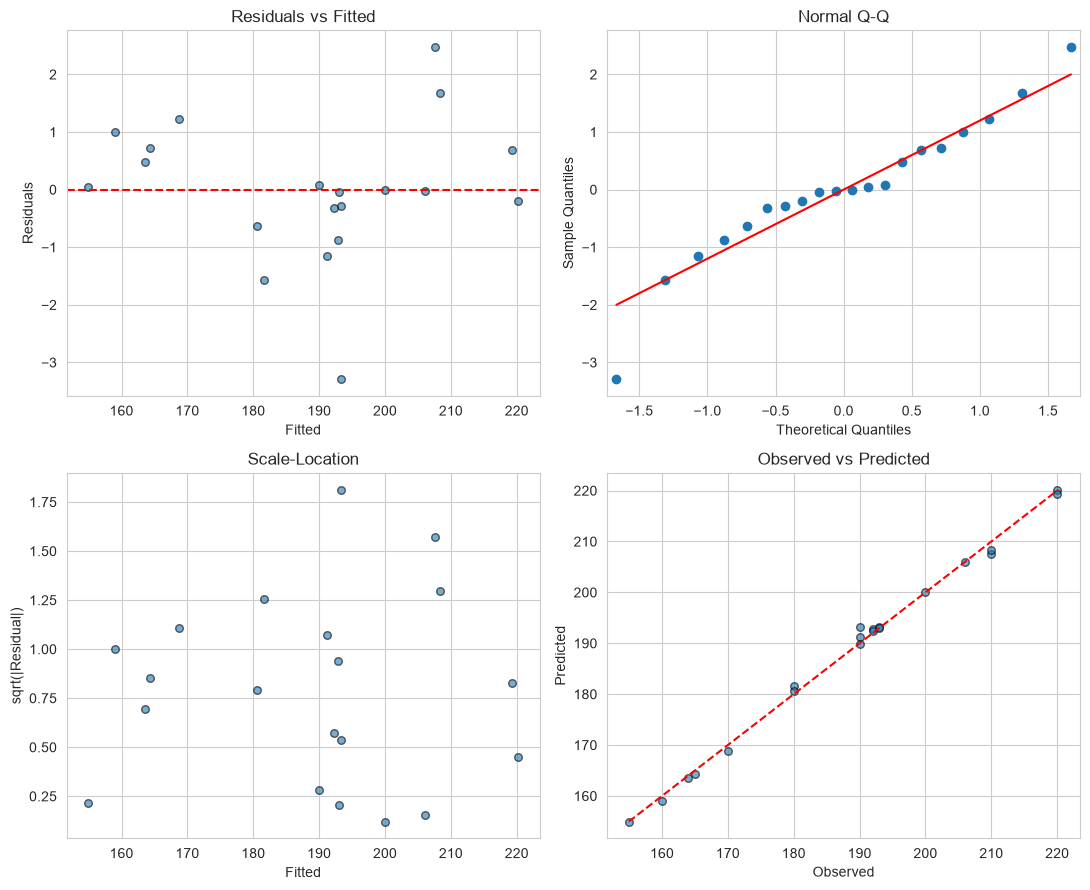

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

axes[0, 0].scatter(model.fittedvalues, resid, edgecolors="k", alpha=0.6, s=30)
axes[0, 0].axhline(0, color="red", ls="--")
axes[0, 0].set_xlabel("Fitted")
axes[0, 0].set_ylabel("Residuals")
axes[0, 0].set_title("Residuals vs Fitted")

sm.qqplot(resid, line="s", ax=axes[0, 1])
axes[0, 1].set_title("Normal Q-Q")

axes[1, 0].scatter(model.fittedvalues, np.sqrt(np.abs(resid)),
                   edgecolors="k", alpha=0.6, s=30)
axes[1, 0].set_xlabel("Fitted")
axes[1, 0].set_ylabel("sqrt(|Residual|)")
axes[1, 0].set_title("Scale-Location")

axes[1, 1].scatter(df["weight"], model.fittedvalues,
                   edgecolors="k", alpha=0.6, s=30)
mn = min(df["weight"].min(), model.fittedvalues.min())
mx = max(df["weight"].max(), model.fittedvalues.max())
axes[1, 1].plot([mn, mx], [mn, mx], "r--")
axes[1, 1].set_xlabel("Observed")
axes[1, 1].set_ylabel("Predicted")
axes[1, 1].set_title("Observed vs Predicted")

plt.tight_layout()
plt.show()


### Выводы по графикам

1. Не наблюдается строгого паттерна, точки разбросаны хаотично, что подтверждает постоянность дисперсии ошибок
2. Наблюдается нормальность, что доказано тестом Шапиро-Уилка, да, есть небольшие отклонения в хвостах, но наверное размер выборки повлиял.
3. Нет чётких паттернов, ошибка не растёт с предсказаниями, следовательно подтверждается гомоскедастичность.
4. График визуально подтверждает коэф. детерминации, точки лежат практически полностью на прямой идеального совпадения.

---
## Шпаргалка по методам (Python)

| Задача | Код |
|--------|-----|
| Модель | `smf.ols("y ~ x1 + x2", data=df).fit()` |
| Сводка | `model.summary()` |
| Остатки / fitted | `model.resid`, `model.fittedvalues` |
| Shapiro остатков | `stats.shapiro(model.resid)` |
| Автокорреляция | `acorr_breusch_godfrey(model, nlags=1)` |
| Гетероскедастичность | `het_breuschpagan(resid, model.model.exog)` |
| MSE | `np.mean(resid**2)` |
| Q–Q plot | `sm.qqplot(resid, line="s")` |

---
## Что сделать после лекции

1. Откройте лабораторное задание и постройте модель **самостоятельно** на указанных данных.
2. Всегда сочетайте числа из `summary()` с графиками остатков.

Удачи!
